# Kolam classification: SMOTE on pixels + CNN
Image → raw pixels → SMOTE on pixels → synthetic images → CNN → test on real images.

In [ ]:
# Connect Google Drive so Colab can read the dataset zip stored there
from google.colab import drive
drive.mount('/content/drive')

# Unzip the dataset into /content (-q means "quiet", so it does not print every file name)
!unzip -q '/content/drive/MyDrive/Kolam_Project/Kolam_Project -.zip' -d '/content/'

# Install the libraries we need (imbalanced-learn is the library that has SMOTE)
!pip install imbalanced-learn -q

Mounted at /content/drive


## Step 1: Load every image as raw pixels

In [ ]:
import os                                  # to work with folders and file names
import numpy as np                         # to store images as arrays of numbers
import torch, torch.nn as nn               # PyTorch, used to build and train the CNN
import matplotlib.pyplot as plt            # to draw pictures and graphs
from PIL import Image                      # to open and resize image files
from sklearn.model_selection import train_test_split     # to split data into train / val / test
from sklearn.preprocessing import LabelEncoder           # to turn class names into numbers
from sklearn.metrics import classification_report        # to print precision / recall / f1
from imblearn.over_sampling import SMOTE                 # the SMOTE method
from sklearn.metrics import f1_score, recall_score     # make sure these are loaded

DATA_DIR = '/content/Kolam_Project -'      # the folder that holds the 9 class folders
SIZE = 64                                  # every image is shrunk to 64 x 64 pixels
                                           # (smaller = less memory and faster training)

# Use the GPU if Colab gives us one (much faster), otherwise use the CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'

X = []          # will hold the images (as pixel numbers)
y = []          # will hold the class name of each image
skipped = 0     # counts files that could not be opened

# Go through each class folder, then each file inside it
for label in sorted(os.listdir(DATA_DIR)):
    folder = os.path.join(DATA_DIR, label)
    if not os.path.isdir(folder):          # skip anything that is not a folder
        continue
    for f in os.listdir(folder):
        try:
            # Open the image, make sure it has 3 colour channels (Red, Green, Blue),
            # and resize it to 64 x 64
            img = Image.open(os.path.join(folder, f)).convert('RGB').resize((SIZE, SIZE))
        except Exception:
            skipped += 1                   # the file is broken or not an image, so skip it
            continue
        # Turn the image into numbers: shape (64, 64, 3), each value is a brightness from 0 to 255
        X.append(np.asarray(img, dtype=np.uint8))
        y.append(label)                    # remember which class this image belongs to

X = np.stack(X)     # join all images into one big array: (number of images, 64, 64, 3)
y = np.array(y)     # turn the list of names into an array
print('Images loaded:', X.shape, '| Files skipped:', skipped)

Images loaded: (6292, 64, 64, 3) | Files skipped: 0


## Step 2: Split into train / validation / test

In [ ]:
# First, take away 20% of the images as the TEST set.
# We never touch it until the very end, so it stays 100% real (no SMOTE images).
# stratify=y keeps the same class proportions in every set.
# random_state=42 means we get the same split every time we run it.
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# From the remaining 80%, take 20% as the VALIDATION set.
# Validation is used for early stopping (deciding when to stop training).
# Result: about 64% train, 16% validation, 20% test.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.2, stratify=y_tmp, random_state=42)

print('Train:', len(X_tr), '| Validation:', len(X_val), '| Test:', len(X_test))

Train: 4026 | Validation: 1007 | Test: 1259


## Step 3: Apply SMOTE on the pixels, then turn the new rows back into images

In [ ]:
# SMOTE only works on rows of numbers, not on 3D images.
# So we flatten each image: 64 x 64 x 3 = 12,288 numbers in one long row.
flat = X_tr.reshape(len(X_tr), -1).astype(np.float32)

# Apply SMOTE to the TRAINING set only.
# For each small class, SMOTE picks an image, finds one of its 5 closest images
# from the same class (k_neighbors=5), and makes a new image "in between" them.
# It keeps doing this until every class has as many images as the biggest class (Mandala).
from collections import Counter
counts = Counter(y_tr)                                  # how many training images each class has
biggest = max(counts.values())                          # Mandala's count
# only top each class up to 50% of Mandala (not 100%), so fewer fake overlay images
target = {c: max(n, int(0.5 * biggest)) for c, n in counts.items()}
X_bal, y_bal = SMOTE(sampling_strategy=target, k_neighbors=5, random_state=42).fit_resample(flat, y_tr)

# Turn each long row back into a 64 x 64 x 3 image.
# round() + clip(0, 255) makes sure every pixel is a whole number between 0 and 255.
X_bal = X_bal.reshape(-1, SIZE, SIZE, 3).round().clip(0, 255).astype(np.uint8)

# SMOTE puts the original images first and adds the new (synthetic) ones at the end.
# So everything after position len(X_tr) is synthetic.
X_syn = X_bal[len(X_tr):]
y_syn = y_bal[len(X_tr):]
print('Training images after SMOTE:', len(X_bal), '| of which synthetic:', len(X_syn))

Training images after SMOTE: 6820 | of which synthetic: 2794


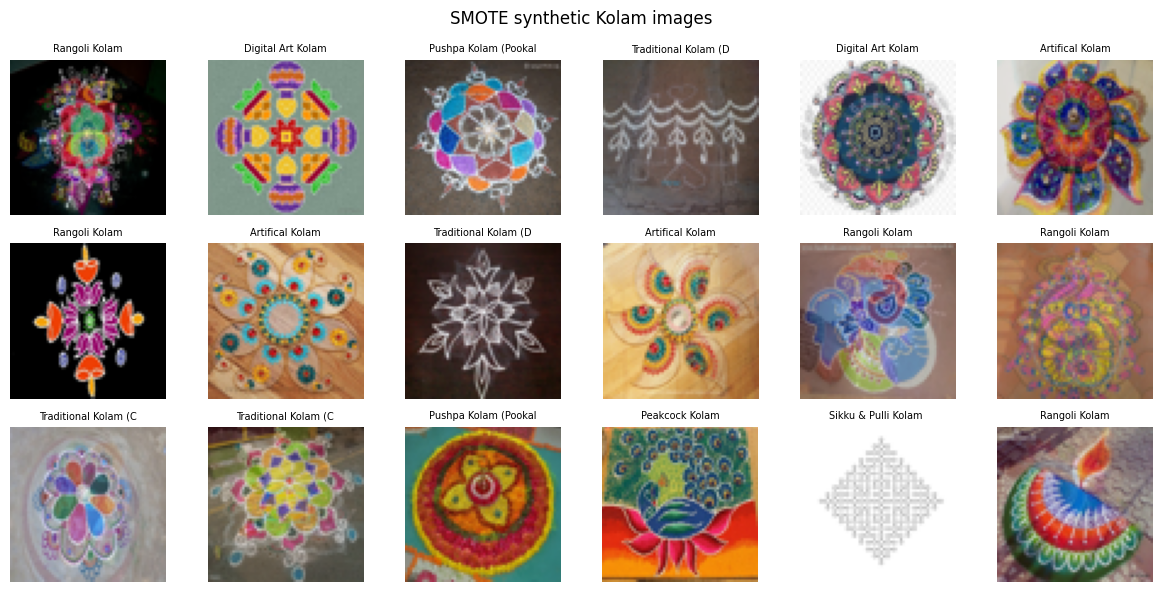

In [ ]:
# Show 18 random synthetic images so we can see what SMOTE made
fig, ax = plt.subplots(3, 6, figsize=(12, 6))           # a grid of 3 rows x 6 columns
picks = np.random.default_rng(0).choice(len(X_syn), 18, replace=False)  # choose 18 at random
for a, k in zip(ax.flat, picks):
    a.imshow(X_syn[k])                                  # draw the image
    a.set_title(y_syn[k][:20], fontsize=7)              # show its class name (first 20 letters)
    a.axis('off')                                       # hide the x/y axis numbers
plt.suptitle('SMOTE synthetic Kolam images')
plt.tight_layout(); plt.show()

## Step 4: Build the CNN and the training function (with early stopping)

In [ ]:
from sklearn.metrics import balanced_accuracy_score
# The CNN needs numbers, not class names, so we turn each name into a number (0 to 8)
le = LabelEncoder().fit(y)

# Helper: turn images into the format PyTorch wants.
# - PyTorch wants (images, channels, height, width), so we move the colour channel to the front
# - divide by 255 so every pixel is between 0 and 1 (easier for the network to learn)
to_t = lambda A: torch.tensor(A, dtype=torch.float32).permute(0, 3, 1, 2).div(255.)

def make_cnn(n_classes=9, dropout=0.3):
    return nn.Sequential(
        # Convolution layer: 32 filters of size 3x3 look for simple patterns (edges, dots, lines).
        # padding=1 adds a border of zeros so the image stays 64 x 64 after the filter.
        nn.Conv2d(3, 32, 3, padding=1),
        nn.ReLU(),                   # keep positive values, turn negative values into 0
        nn.MaxPool2d(2),             # keep the strongest value in each 2x2 area: 64x64 -> 32x32

        # Second convolution: 64 filters look for bigger patterns built from the simple ones
        nn.Conv2d(32, 64, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),             # 32x32 -> 16x16

        # Third convolution: 128 filters look for even bigger shapes (petals, loops, grids)
        nn.Conv2d(64, 128, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),             # 16x16 -> 8x8

        nn.Flatten(),                # turn the 128 x 8 x 8 result into one long row of 8,192 numbers
        nn.Linear(128 * 8 * 8, 256), # fully connected layer: 8,192 numbers -> 256 numbers
        nn.ReLU(),
        nn.Dropout(dropout),         # randomly switch off 30% of neurons during training (stops memorising)
        nn.Linear(256, n_classes))   # final layer: 256 numbers -> 9 scores, one per Kolam class

# Helper: get the model's predictions, 256 images at a time (so the GPU does not run out of memory)
@torch.no_grad()                     # no learning here, only predicting
def predict(model, A, bs=256):
    model.eval()                     # switch to "test mode" (turns dropout off)
    return torch.cat([model(to_t(A[i:i+bs]).to(device)).cpu() for i in range(0, len(A), bs)])

def train_cnn(Xa, ya, seed=42, lr=1e-3, batch=64, dropout=0.3, max_epochs=50, patience=10):
    torch.manual_seed(seed)
    model = make_cnn(dropout=dropout).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    Xt = to_t(Xa)
    yt = torch.tensor(le.transform(ya))
    yv = le.transform(y_val)

    best_score = 0                   # best balanced accuracy so far (higher = better)
    wait = 0

    for ep in range(max_epochs):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = loss_fn(model(Xt[idx].to(device)), yt[idx].to(device))
            loss.backward()
            opt.step()

        # judge each epoch by BALANCED ACCURACY on validation
        # (average recall over the 9 classes, so small classes count as much as Mandala)
        score = balanced_accuracy_score(yv, predict(model, X_val).argmax(1).numpy())

        if score > best_score:
            best_score, wait = score, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:     # no improvement for 10 epochs in a row -> stop
                break

    model.load_state_dict(best_state)
    print(f'Stopped at epoch {ep+1}, best validation balanced accuracy {best_score:.4f}')
    return model

## Proof 1: How often does each model guess each class?
Without SMOTE the model should guess Mandala too often. With SMOTE the guesses should be closer to the real counts.

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, recall_score

classes = list(le.classes_)                       # the 9 class names

# Helper: train a CNN and return its predicted class name for every test image
def run(Xa, ya, seed):
    m = train_cnn(Xa, ya, seed=seed)
    return le.inverse_transform(predict(m, X_test).argmax(1).numpy())

pred_smote = run(X_bal, y_bal, seed=42)           # model trained WITH SMOTE
pred_none  = run(X_tr,  y_tr,  seed=42)           # model trained WITHOUT SMOTE

# Table: for each class, how many test images really belong to it, and how many times each model guessed that class
table = pd.DataFrame({
    'Real count in test':   pd.Series(y_test).value_counts(),
    'Predicted (no SMOTE)': pd.Series(pred_none).value_counts(),
    'Predicted (SMOTE)':    pd.Series(pred_smote).value_counts(),
}).reindex(classes).fillna(0).astype(int)
print(table)

Stopped at epoch 24, best validation balanced accuracy 0.6873
Stopped at epoch 29, best validation balanced accuracy 0.6863
                                           Real count in test  \
Artifical Kolam                                            38   
Digital Art Kolam                                         117   
Mandala Kolam                                             427   
Peakcock Kolam                                            103   
Pushpa Kolam (Pookalam)                                    72   
Rangoli Kolam                                              89   
Sikku & Pulli Kolam (Geometric Patterns)                  123   
Traditional Kolam (Colourful)                             124   
Traditional Kolam (Dominant White Colour)                 166   

                                           Predicted (no SMOTE)  \
Artifical Kolam                                              27   
Digital Art Kolam                                           103   
Mandala Kolam           

## Proof 2: Confusion matrices
Diagonal = recall of each class (higher is better).
The Mandala column = how often other classes are wrongly called Mandala (lower is better).

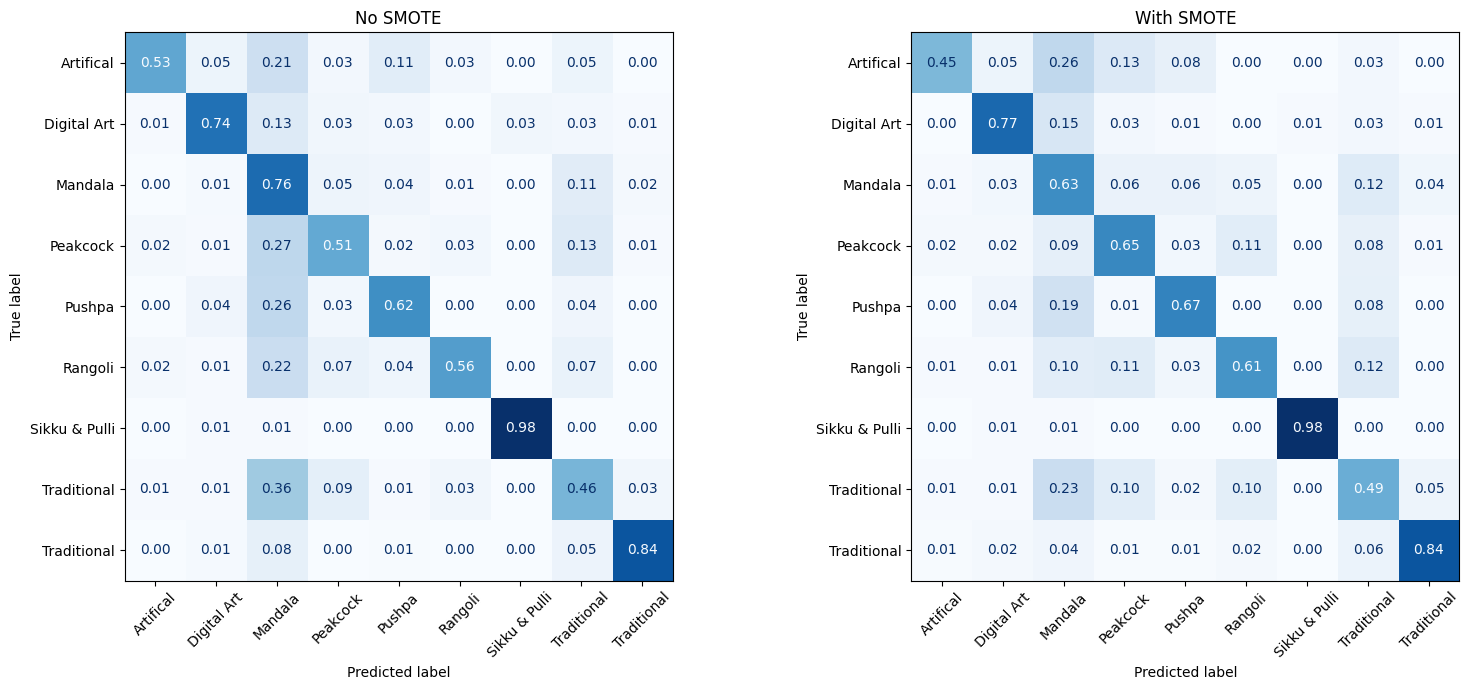

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
short = [c.split(' (')[0].replace(' Kolam', '') for c in classes]   # shorter labels for the plot
for a, (name, p) in zip(ax, [('No SMOTE', pred_none), ('With SMOTE', pred_smote)]):
    # normalize='true' turns each row into fractions, so the diagonal = recall of that class
    cm = confusion_matrix(y_test, p, labels=classes, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=short).plot(ax=a, cmap='Blues', values_format='.2f',
                                                          colorbar=False, xticks_rotation=45)
    a.set_title(name)
plt.tight_layout(); plt.show()

## Proof 3: SMOTE on the CNN's learned features
Same CNN per seed; only the final layer is retrained, with vs without SMOTE on its 256 features.

In [ ]:
# Proof 3: SMOTE on the CNN's learned features (not on raw pixels)
# Idea: the CNN's last hidden layer turns each image into 256 numbers that describe it.
# Blending two of these descriptions gives a sensible "in-between Kolam" (no double-exposure images).
# For each seed:
#   1) train the CNN on REAL images only
#   2) turn every image into its 256 features
#   3) retrain ONLY the final layer twice: on the real features, and on SMOTE-balanced features
# Both final layers use the SAME CNN, so the only difference is SMOTE.

import pandas as pd
from sklearn.metrics import recall_score, f1_score, balanced_accuracy_score
from scipy.stats import ttest_rel

classes = list(le.classes_)          # the 9 class names
N_SEEDS = 10                         # number of repeats

# Helper: pass images through every layer EXCEPT the last one -> 256 numbers per image
@torch.no_grad()
def get_features(model, A, bs=256):
    model.eval()
    body = model[:-1]                # all layers except the final Linear(256, 9)
    return torch.cat([body(to_t(A[i:i+bs]).to(device)).cpu() for i in range(0, len(A), bs)]).numpy()

# Helper: train a new final layer (256 numbers -> 9 class scores) with early stopping
def train_head(F, yl, Fv, seed, lr=1e-3, batch=64, max_epochs=200, patience=10):
    torch.manual_seed(seed)
    head = nn.Linear(F.shape[1], len(classes)).to(device)     # the final layer only
    opt = torch.optim.AdamW(head.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    Ft  = torch.tensor(F,  dtype=torch.float32).to(device)    # training features
    yt  = torch.tensor(le.transform(yl)).to(device)           # training labels as numbers
    Fvt = torch.tensor(Fv, dtype=torch.float32).to(device)    # validation features
    yv  = le.transform(y_val)                                 # validation labels as numbers
    best, wait = 0, 0
    for ep in range(max_epochs):
        head.train()
        perm = torch.randperm(len(Ft), device=device)         # shuffle every epoch
        for i in range(0, len(Ft), batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss_fn(head(Ft[idx]), yt[idx]).backward()
            opt.step()
        head.eval()
        with torch.no_grad():                                 # judge by balanced accuracy on validation
            score = balanced_accuracy_score(yv, head(Fvt).argmax(1).cpu().numpy())
        if score > best:
            best, wait = score, 0
            state = {k: v.clone() for k, v in head.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break                        # early stopping
    head.load_state_dict(state)
    return head

rows = []
for s in range(N_SEEDS):
    cnn = train_cnn(X_tr, y_tr, seed=s)                       # 1) CNN trained on REAL images only
    F_tr  = get_features(cnn, X_tr)                           # 2) 256 features for every image
    F_val = get_features(cnn, X_val)
    F_te  = get_features(cnn, X_test)
    F_bal, y_fbal = SMOTE(k_neighbors=5, random_state=s).fit_resample(F_tr, y_tr)   # 3) SMOTE on features

    for name, (F, yl) in {'No SMOTE': (F_tr, y_tr), 'Feature SMOTE': (F_bal, y_fbal)}.items():
        head = train_head(F, yl, F_val, seed=s)               # retrain the final layer
        with torch.no_grad():
            scores = head(torch.tensor(F_te, dtype=torch.float32).to(device))
        p = le.inverse_transform(scores.argmax(1).cpu().numpy())   # predicted class names for the test set
        r = recall_score(y_test, p, labels=classes, average=None)
        rows.append({'seed': s, 'setup': name,
                     'accuracy': (p == y_test).mean(),
                     'balanced_acc': balanced_accuracy_score(y_test, p),
                     'macro_f1': f1_score(y_test, p, average='macro'),
                     **dict(zip(classes, r))})
df4 = pd.DataFrame(rows)

# Recall per class: mean ± std over all seeds
mean = df4.groupby('setup')[classes].mean().T
std  = df4.groupby('setup')[classes].std().T
print(f'Recall per class (mean ± std over {N_SEEDS} seeds):')
print(mean.round(2).astype(str) + ' ± ' + std.round(2).astype(str))

# Overall scores
print(df4.groupby('setup')[['accuracy', 'balanced_acc', 'macro_f1']].agg(['mean', 'std']).round(3))

# Average recall of the 8 minority classes, then paired t-test seed by seed
minority = [c for c in classes if c != 'Mandala Kolam']
df4['minority_recall'] = df4[minority].mean(axis=1)
a = df4[df4.setup == 'Feature SMOTE'].sort_values('seed')['minority_recall'].values
b = df4[df4.setup == 'No SMOTE'].sort_values('seed')['minority_recall'].values
print('Minority recall   Feature SMOTE:', a.mean().round(3), '| No SMOTE:', b.mean().round(3))
print('Paired t-test p-value:', round(ttest_rel(a, b).pvalue, 4))


Stopped at epoch 44, best validation balanced accuracy 0.6894
Stopped at epoch 28, best validation balanced accuracy 0.6937
Stopped at epoch 28, best validation balanced accuracy 0.7032
Stopped at epoch 41, best validation balanced accuracy 0.6953
Stopped at epoch 33, best validation balanced accuracy 0.6900
Stopped at epoch 43, best validation balanced accuracy 0.6899
Stopped at epoch 26, best validation balanced accuracy 0.6840
Stopped at epoch 31, best validation balanced accuracy 0.6912
Stopped at epoch 28, best validation balanced accuracy 0.6874
Stopped at epoch 27, best validation balanced accuracy 0.6786
Recall per class (mean ± std over 10 seeds):
setup                                     Feature SMOTE     No SMOTE
Artifical Kolam                             0.59 ± 0.06   0.5 ± 0.05
Digital Art Kolam                           0.78 ± 0.03  0.76 ± 0.03
Mandala Kolam                               0.66 ± 0.05  0.75 ± 0.02
Peakcock Kolam                              0.54 ± 0.03  0.